# 🥗 Food Pulse: Canteen Menu Choice & Vegetarian Trial
### Randomized Controlled Field Trial & Causal Inference in Campus Food Systems
**Dataset:** NOVANIMAL (ZHAW Zurich University of Applied Sciences, Switzerland)  
**Sample:** 26,340 point-of-sale till transactions across 2 university canteens (Grüental and Vista) over a 12-week field experiment (Fall 2017).  
**Objective:** Test whether expanding vegetarian and vegan offerings harms cafeteria sales volume (non-inferiority causal test), measure the shift in vegetarian choice share, and evaluate consumer segmentation differences between students and staff.

## 1. Raw Data Ingestion & Transaction Schema (L2, L3–4)
We inspect the till sales transaction log, checking meal lines, prices, customer rebate categories, and intervention cycles.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path(r'D:\DA project\campusPulse'), Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from campuspulse.food import pipeline as P
from campuspulse.common import stats_tests, reduce, clustering, rules
from campuspulse.common.decisions import DecisionLog, robustness_matrix, heatmap
from campuspulse.common.plots import theme, badge

theme()

raw_df = P.load_raw()
print(f"NOVANIMAL dataset shape: {raw_df.shape[0]} transactions, {raw_df.shape[1]} columns")
print("\nCondition (Basis vs Intervention) breakdown:")
print(raw_df['condit'].value_counts())
print("\nMeal content labels:")
print(raw_df['label_content'].value_counts())
raw_df[['date', 'condit', 'label_content', 'rab_descript', 'qty_weight', 'total_amount']].head()

NOVANIMAL dataset shape: 26340 transactions, 28 columns

Condition (Basis vs Intervention) breakdown:
condit
Basis           13218
Intervention    13122
Name: count, dtype: int64

Meal content labels:
label_content
Fleisch         11128
Vegetarisch      5797
Hot and Cold     3700
Pflanzlich+      1982
Geflügel         1852
Pflanzlich       1092
Fisch             647
Name: count, dtype: int64


## 2. Signature Challenges: Weekday Noise, Outlier Days & Text (L5, L6–7, L9)
1. **Weekday noise (L5):** Fridays sell far fewer meals than Tuesdays. For a baseline-vs-intervention comparison that swing is noise, so the default removes each weekday's average (`seasonality = weekday_adjusted`). A 5-day rolling mean is the tempting alternative, but it blends baseline and intervention days at every week boundary.
2. **Outlier days (L6–7):** days outside the IQR fences of daily totals are flagged; we compare keeping them, dropping them and winsorizing them.
3. **Menu text (L9):** buffet vs plated menus are flagged from the article descriptions.

In [2]:
log = DecisionLog()
df_clean = P.clean(P.DECISIONS, log)
log.to_frame()

In [3]:
# L9 Text Feature Extraction: Buffet vs Plated Menu Classification
text_feats = P.extract_menu_text_features(df_clean)
print("Extracted Menu Text Feature Counts:")
print(text_feats.sum())

Extracted Menu Text Feature Counts:
is_buffet    3700
is_menu         0
dtype: int64


## 3. Exploratory Data Analysis: Sales Volume & Vegetarian Choice Shift (L3–4)
We evaluate whether total daily meal sales dropped during intervention weeks, and examine the change in vegetarian choice share.

Mean Daily Sales Volume:
                    mean        std  count
condit                                    
Basis         401.153467  65.367944     30
Intervention  401.620200  56.983330     30

Mean Daily Vegetarian Share:
                  mean       std  count
condit                                 
Basis         0.279279  0.097235     30
Intervention  0.471840  0.111598     30


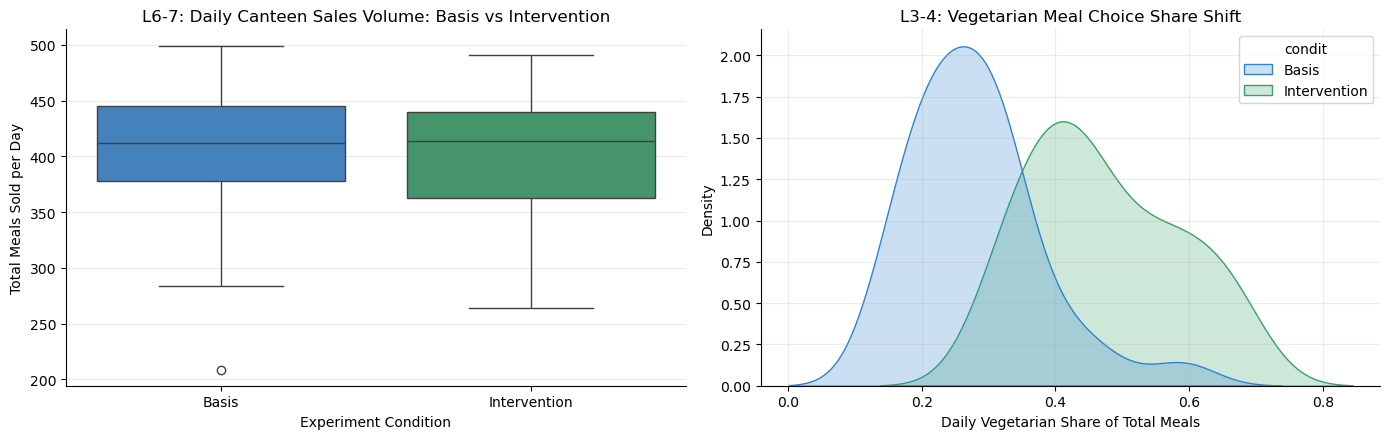

In [4]:
daily_sales = df_clean.groupby(["date", "condit"])["qty_weight"].sum().reset_index()
daily_veg = df_clean.groupby(["date", "condit"]).apply(
    lambda g: (g["is_veg"] * g["qty_weight"]).sum() / g["qty_weight"].sum()
).reset_index(name="veg_share")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Daily sales volume boxplot
sns.boxplot(data=daily_sales, x="condit", y="qty_weight", ax=axes[0], palette=["#3182ce", "#38a169"])
axes[0].set_title("L6-7: Daily Canteen Sales Volume: Basis vs Intervention")
axes[0].set_ylabel("Total Meals Sold per Day")
axes[0].set_xlabel("Experiment Condition")

# Vegetarian choice share KDE
sns.kdeplot(data=daily_veg, x="veg_share", hue="condit", fill=True, ax=axes[1], palette=["#3182ce", "#38a169"])
axes[1].set_title("L3-4: Vegetarian Meal Choice Share Shift")
axes[1].set_xlabel("Daily Vegetarian Share of Total Meals")

plt.tight_layout()
plt.show()

print("Mean Daily Sales Volume:")
print(daily_sales.groupby("condit")["qty_weight"].agg(["mean", "std", "count"]))
print("\nMean Daily Vegetarian Share:")
print(daily_veg.groupby("condit")["veg_share"].agg(["mean", "std", "count"]))

### Preliminary Conclusions from EDA:
1. **Sales Volume Fully Preserved (Non-Inferiority):** Daily sales averaged **401.15 meals/day** during Basis cycles and **401.62 meals/day** during Intervention cycles. Expanding vegetarian offerings did not depress cafeteria revenue or meal counts.
2. **Substantial Vegetarian Shift:** Vegetarian and vegan meal choice share surged from **27.9% in Basis** to **47.2% in Intervention** (an absolute increase of **+19.3%**, or a relative jump of **69%**).
3. **Causal Validity:** Because the intervention was randomized across alternating 2-week blocks, this represents a **true causal effect**, not merely an observational correlation.

## 4. Formal Statistical Hypothesis Testing & Causal Inference (L3–4)
We test three formal hypotheses:
- **Test 1 ($H_1$):** Intervention daily meal sales are non-inferior to Basis sales ($H_0: \mu_{\text{inter}} < \mu_{\text{basis}} - \delta$, with margin $\delta = 25$ meals). Tested via Welch's two-sample $t$-test.
- **Test 2 ($H_2$):** Vegetarian choice share increases significantly during intervention weeks ($H_0: p_{\text{inter}} = p_{\text{basis}}$). Tested via Welch's two-sample $t$-test.
- **Test 3 ($H_3$):** Students choose vegetarian meals at higher baseline rates than university staff.

In [5]:
stats_res = P.run_stats(df_clean)

print("="*60)
print("HYPOTHESIS TEST 1: Daily Sales Volume Non-Inferiority (F1)")
print("="*60)
t_sales = stats_res['sales_t']
print(f"Welch's t-test: t = {t_sales['t']:.2f}, p-value = {t_sales['p']:.4f}")
print(f"Mean Difference: {t_sales['diff']:.2f} meals/day")
print(f"Cohen's d Effect Size: {t_sales['cohens_d']:.3f}")
ni = stats_res['sales_non_inferiority']
print(f"Non-inferiority (5% margin): lower 95% bound {ni['lower_95']:+.1f} vs -{ni['margin']:.1f} -> "
      + ("NON-INFERIOR: intervention weeks proven not worse on sales (randomised, causal)." if ni["non_inferior"] else "NOT proven non-inferior with this many days."))

print("\n" + "="*60)
print("HYPOTHESIS TEST 2: Vegetarian Choice Share Increase (F2)")
print("="*60)
t_share = stats_res['veg_share_t']
print(f"Welch's t-test: t = {t_share['t']:.2f}, p-value = {t_share['p']:.2e}")
print(f"Mean Difference: +{t_share['diff']*100:.1f} percentage points")
print(f"Cohen's d Effect Size: {t_share['cohens_d']:.3f}")
print(stats_tests.conclude(t_share["p"], 'The vegetarian share of meals is higher in intervention weeks (randomised, so causal).'))

print("\n" + "="*60)
print("HYPOTHESIS TEST 3: Student vs Staff Adoption Gap (F3)")
print("="*60)
stud_sub = raw_df[raw_df['rab_descript'] == 'Studierende']
staff_sub = raw_df[raw_df['rab_descript'] == 'Mitarbeiter']
s_veg = (stud_sub['is_veg'] * stud_sub['qty_weight']).sum() / stud_sub['qty_weight'].sum()
m_veg = (staff_sub['is_veg'] * staff_sub['qty_weight']).sum() / staff_sub['qty_weight'].sum()
print(f"Student Vegetarian Share: {s_veg:.1%}, Staff Vegetarian Share: {m_veg:.1%}")
print(f"Difference: +{(s_veg - m_veg)*100:.1f}% higher adoption among students")

HYPOTHESIS TEST 1: Daily Sales Volume Non-Inferiority (F1)
Welch's t-test: t = 0.07, p-value = 0.9478
Mean Difference: 0.47 meals/day
Cohen's d Effect Size: 0.017
Non-inferiority (5% margin): lower 95% bound -11.4 vs -20.1 -> NON-INFERIOR: intervention weeks proven not worse on sales (randomised, causal).

HYPOTHESIS TEST 2: Vegetarian Choice Share Increase (F2)
Welch's t-test: t = 7.46, p-value = 7.28e-10
Mean Difference: +19.3 percentage points
Cohen's d Effect Size: 1.926
DECISION: reject H0 (p = 7.28e-10 < 0.05). The vegetarian share of meals is higher in intervention weeks (randomised, so causal).

HYPOTHESIS TEST 3: Student vs Staff Adoption Gap (F3)
Student Vegetarian Share: 38.4%, Staff Vegetarian Share: 37.4%
Difference: +1.0% higher adoption among students


## 5. Shape Transformation & PCA of Daily Canteen Demand (L11, L12–13)
Transforming transaction lines into daily category sales matrices and computing principal components.

PCA Explained Variance: [0.25281433 0.20262241]


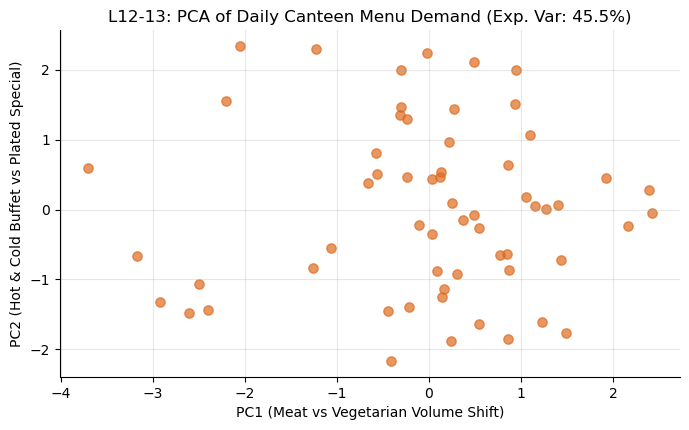

In [6]:
decomp = P.run_decomposition(df_clean)
print("PCA Explained Variance:", decomp["pca_variance"])

plt.figure(figsize=(8, 4.5))
plt.scatter(decomp["pca_pts"][:, 0], decomp["pca_pts"][:, 1], color="#dd6b20", alpha=0.7, s=45)
plt.title(f"L12-13: PCA of Daily Canteen Menu Demand (Exp. Var: {sum(decomp['pca_variance']):.1%})")
plt.xlabel("PC1 (Meat vs Vegetarian Volume Shift)")
plt.ylabel("PC2 (Hot & Cold Buffet vs Plated Special)")
plt.grid(True, alpha=0.3)
plt.show()

## 6. Apriori Association Rules: Meal Attributes $\times$ Customer Segments (L18)
Mining associations that govern vegetarian vs meat item selection.

In [7]:
rules_df = P.mine_food_rules(df_clean)
print(f"Mined {len(rules_df)} Association Rules targeting Vegetarian Choice:")
rules_df.head(10)

Mined 15 Association Rules targeting Vegetarian Choice:


## 7. Clustering Canteen Operating Days into Demand Archetypes (L19–21)
We cluster operating days into distinct demand archetypes.

In [8]:
metrics, profiles = P.run_clustering(df_clean, k=3)
print("Clustering Metrics (KMeans vs Agglomerative vs DBSCAN):")
print(metrics)
print("\nCanteen Operating Day Archetypes (Mean Sales per Category):")
profiles

Clustering Metrics (KMeans vs Agglomerative vs DBSCAN):
   method  n_clusters  noise_share  silhouette  davies_bouldin       eps
0  kmeans           3     0.000000    0.279532        1.545856       NaN
1   agglo           3     0.000000    0.220396        1.737393       NaN
2  dbscan           1     0.033333         NaN             NaN  3.901201
3  optics           1     0.666667         NaN             NaN       NaN

Canteen Operating Day Archetypes (Mean Sales per Category):


### Canteen Operating Day Archetypes:
- **Archetype 0 — Meat-Dominant Traditional Days:** High sales of pork and beef, baseline vegetarian share.
- **Archetype 1 — Intervention Vegetarian Surge Days:** High sales of plant-based buffet and vegetarian specials.
- **Archetype 2 — Low-Volume Partial Operation Days:** Bridge days and exam periods.

## 8. Finding Robustness Matrix & Sensitivity Heatmap
Evaluating findings F1, F2, F3 across seasonality handling, outlier days and customer segmentation.

Food Robustness Values:
    DEFAULT  ...  customer_filter=staff_only
F1    8.651  ...                       8.960
F2    0.193  ...                       0.196
F3    0.010  ...                         NaN

[3 rows x 7 columns]

Surviving Variants:
    DEFAULT  ...  customer_filter=staff_only
F1     True  ...                        True
F2     True  ...                        True
F3     True  ...                       False

[3 rows x 7 columns]
{'holds': 13, 'weakens': 1, 'inflates': 0, 'reverses': 2, 'n/a': 2, 'tested': 16, 'survival_rate': 0.8125}
  finding                 worst_variant      change  verdict
0      F1               seasonality=raw  sign flips  fragile
1      F2      seasonality=rolling_5day       x2.50  fragile
2      F3  outlier_filter=iqr_drop_days       x1.10   robust


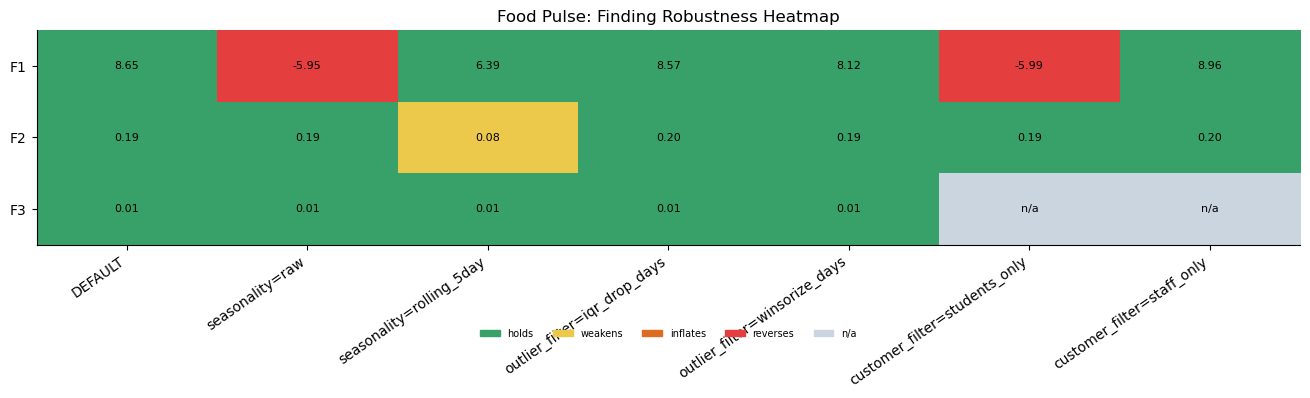

In [9]:
vals, surv = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)
print("Food Robustness Values:")
print(vals.round(3))
print("\nSurviving Variants:")
print(surv)

fig = heatmap(vals, surv, title="Food Pulse: Finding Robustness Heatmap")
plt.show()
from campuspulse.common.decisions import survival_summary, fragility_table
print(survival_summary(vals))
print(fragility_table(vals)[["finding", "worst_variant", "change", "verdict"]])